# 22. Hợp nhất chỉ số của mọi cấu hình

Mười lần chạy của tuần 3 đã sinh ra mười tệp tổng hợp riêng, mỗi tệp dùng một quy ước khoá và một tập cấu hình khác nhau. Khi viết báo cáo, việc phải mở mười tệp để lấy từng con số là nguồn sai sót lớn nhất: cùng một cấu hình có thể xuất hiện ở ba tệp với ba giá trị hơi khác nhau vì số hạt giống khác nhau, và người đọc không có cách nào biết con số nào mới là con số chính thức.

Sổ tay này giải bài toán đó bằng một sổ đăng ký duy nhất. Nó quét mọi tệp mô tả lần huấn luyện trong `Output/processed`, giữ lại đúng các lần khớp điều kiện ghép, rồi dựng hai bảng: bảng theo từng lần huấn luyện và bảng theo từng cấu hình. Mọi sổ tay sau trong đợt này, và mọi con số trong báo cáo tuần 3, đều lấy từ hai bảng đó.

Một lần huấn luyện chỉ được xếp hạng chung khi khớp đủ bốn điều kiện: cùng lần chạy nguồn, cùng độ dài hai cửa sổ, cùng mốc Persistence và cùng tổng số điểm chấm trên tập kiểm tra. Mốc Persistence trùng nhau chưa đủ, vì một lần chạy có thể tính mốc trên giao thức chính nhưng chấm mô hình trên một tập điểm hẹp hơn, chẳng hạn chỉ các điểm có sự kiện đo. Các lần như vậy được tách sang một khối riêng có nhãn giao thức, giữ lại để truy vết và đối chiếu, nhưng không vào bảng xếp hạng.

Phạm vi quét được khoá ở tuần 3. Thư mục `Output/processed` hiện chứa thêm các lần chạy của tuần 4, chẳng hạn quét ngưỡng Huber của notebook 28 và nhánh đặc trưng tĩnh của notebook 30. Các lần đó ghi cùng họ mô hình, cùng neo B và cùng hàm Huber như cấu hình nền của tuần 3, nhưng khác ngưỡng Huber hoặc có thêm nhánh tĩnh. Nếu để chúng vào sổ đăng ký, chúng sẽ rơi vào cùng khoá với cấu hình nền và làm sai trung bình. Vì vậy mọi thư mục mang tiền tố tuần 4 trở đi bị loại có ghi lý do, và khoá cấu hình được mở rộng thêm ngưỡng Huber cùng trạng thái nhánh tĩnh như một lớp phòng thủ thứ hai. Cuối ô gộp bản sao, cấu hình nền neo B hàm Huber được đối chiếu chéo với chính con số mà notebook 29 đã dùng, để tuần 3 và tuần 4 cùng đứng trên một nền.

Sổ tay không huấn luyện mô hình nào, không cần bộ xử lý đồ họa, chi phí dưới hai phút.

> **Vị trí trong chuỗi tái lập:** notebook 22 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 09-Ba_ham_mat_mat_hai_neo, 10-Luoi_nam_hat_giong, 11-Chi_so_theo_nhom_kenh, 12-Phan_tang_theo_do_tre, 13-Moc_trung_binh_dich_chuyen, 14-Doi_chung_moc_manh_nhat, 15-Neo_B_ham_tuyet_doi_nam_hat_giong, 16-Kiem_tra_thang_do_kenh, 17-Neo_theo_nguong_do_phu, 18-Phan_tang_gop_tang_cuoi, 19-DLinear_neo_B_giao_thuc_chinh, 20-Neo_A_ham_tuyet_doi_nam_hat_giong, 21-Neo_theo_ty_le_trung_neo.
>
> **Thư mục kết quả:** `Output/processed/w3_artefacts_tong_hop/`.
>
> **Mã định danh nội bộ:** `W3.W4_26`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_artefacts_tong_hop"  #@param {type:"string"}
LAM_TRON_IN = 6  #@param {type:"integer"}
TONG_DIEM_KY_VONG = 136752  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:50:56
run_tag      w3_artefacts_tong_hop
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


In [4]:
# Đợt hợp nhất dùng thêm hai thư mục con để tách bảng và gói nộp.
OUT_PROC = OUT / "processed"
BANG = RUN_DIR / "bang"
GOI = RUN_DIR / "goi"
for d in (BANG, GOI):
    d.mkdir(parents=True, exist_ok=True)


def ghi_bang(ten, cot, hang):
    """Ghi một bảng ra tệp CSV, dùng bảng mã có dấu hiệu thứ tự byte cho Excel."""
    import csv
    duong = BANG / ten
    with open(duong, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(cot)
        for r in hang:
            w.writerow([r.get(k, "") for k in cot])
    print("Đã ghi bảng", ten, "|", len(hang), "dòng |",
          duong.stat().st_size, "byte")
    return duong


def ghi_json(ten, doi_tuong):
    """Ghi một tệp tổng hợp, luôn giữ nguyên dấu tiếng Việt."""
    duong = RUN_DIR / ten
    duong.write_text(json.dumps(doi_tuong, ensure_ascii=False, indent=1),
                     encoding="utf-8")
    print("Đã ghi tệp", ten, "|", duong.stat().st_size, "byte")
    return duong


print("Thư mục bảng:", BANG)
print("Thư mục gói :", GOI)


Thư mục bảng: /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/bang
Thư mục gói : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/goi


## 2. Danh mục mười lần chạy của tuần 3

Danh mục được khai báo tường minh thay vì dò theo mẫu tên, vì tên tệp tổng hợp của mỗi sổ tay do chính sổ tay đó đặt và không theo một mẫu chung. Khai báo tường minh cho phép phát hiện ngay lần chạy nào còn thiếu, và chặn luôn việc hợp nhất trên dữ liệu không đầy đủ.

In [5]:
# Danh mục mười lần chạy của tuần 3, khai báo tường minh theo ba thành phần:
# Mã sổ tay, tên thư mục con và tên tệp tổng hợp mà sổ tay đó đã ghi ra.
DANH_MUC_W3 = [
    ("W3_16", "w3_16_ba_ham_mat_mat_hai_neo", "W3_ba_ham_mat_mat_hai_neo.json"),
    ("W3_17", "w3_17_luoi_nam_hat_giong", "W3_luoi_nam_hat_giong.json"),
    ("W3_18", "w3_18_chi_so_theo_nhom_kenh", "W3_chi_so_theo_nhom_kenh.json"),
    ("W3_19", "w3_19_phan_tang_theo_do_tre", "W3_phan_tang_theo_do_tre.json"),
    ("W3_20", "w3_20_moc_trung_binh_dich_chuyen",
     "W3_moc_trung_binh_dich_chuyen.json"),
    ("W3_21", "w3_21_doi_chung_moc_manh_nhat", "W3_doi_chung_moc_manh_nhat.json"),
    ("W3_22", "w3_22_neo_b_ham_tuyet_doi_nam_hat_giong",
     "W3_neo_b_mae_nam_hat_giong.json"),
    ("W3_23", "w3_23_kiem_tra_thang_do_kenh", "W3_kiem_tra_thang_do_kenh.json"),
    ("W3_24", "w3_24_neo_theo_nguong_do_phu", "W3_neo_theo_nguong_do_phu.json"),
    ("W3_25", "w3_25_phan_tang_gop_tang_cuoi",
     "W3_phan_tang_gop_tang_cuoi.json"),
]


# Ba sổ tay bổ sung huấn luyện mô hình mới trên giao thức chính. Chúng là tuỳ chọn:
# Có tệp tổng hợp thì đọc, chưa có thì bỏ qua và in rõ.
DANH_MUC_BO_SUNG = [
    ("W3_31", "w3_31_dlinear_neo_b_giao_thuc_chinh",
     "W3_dlinear_neo_b_giao_thuc_chinh.json"),
    ("W3_32", "w3_32_neo_theo_ty_le_trung_neo", "W3_neo_theo_ty_le_trung_neo.json"),
    ("W3_33", "w3_33_neo_a_ham_tuyet_doi_nam_hat_giong",
     "W3_neo_a_mae_nam_hat_giong.json"),
]


def doc_tong_hop(ma):
    """Đọc tệp tổng hợp của một sổ tay tuần 3 theo mã sổ tay."""
    for m, thu_muc, ten_tep in DANH_MUC_W3 + DANH_MUC_BO_SUNG:
        if m == ma:
            duong = OUT / "processed" / thu_muc / ten_tep
            assert duong.exists(), "Không thấy " + str(duong)
            return json.loads(duong.read_text())
    raise KeyError("Không có mã sổ tay " + str(ma))


CO_MAT, THIEU = [], []
for ma, thu_muc, ten_tep in DANH_MUC_W3:
    duong = OUT / "processed" / thu_muc / ten_tep
    (CO_MAT if duong.exists() else THIEU).append(ma)
print("Lần chạy đã có tệp tổng hợp:", ", ".join(CO_MAT))
print("Lần chạy còn thiếu        :", ", ".join(THIEU) if THIEU else "không có")
assert not THIEU, ("Còn thiếu tệp tổng hợp của " + ", ".join(THIEU) +
                   ". Hãy chạy lại các sổ tay đó trước khi hợp nhất.")

BO_SUNG_CO_MAT = [ma for ma, thu_muc, ten_tep in DANH_MUC_BO_SUNG
                  if (OUT / "processed" / thu_muc / ten_tep).exists()]
print("Sổ tay bổ sung đã có tệp tổng hợp:",
      ", ".join(BO_SUNG_CO_MAT) if BO_SUNG_CO_MAT else "chưa có")
if len(BO_SUNG_CO_MAT) < len(DANH_MUC_BO_SUNG):
    print("Ghi chú: sổ tay bổ sung nào chưa chạy thì cấu hình của nó chưa có trong bảng xếp hạng")


Lần chạy đã có tệp tổng hợp: W3_16, W3_17, W3_18, W3_19, W3_20, W3_21, W3_22, W3_23, W3_24, W3_25
Lần chạy còn thiếu        : không có
Sổ tay bổ sung đã có tệp tổng hợp: W3_31, W3_32, W3_33


## 3. Quét sổ đăng ký các lần huấn luyện

Mỗi lần huấn luyện đã ghi lại một tệp mô tả cạnh trọng số. Sổ tay đọc toàn bộ các tệp đó, nhưng chỉ nhận những lần khớp đủ ba điều kiện ghép: cùng lần chạy nguồn, cùng độ dài hai cửa sổ, cùng giao thức lưới. Ô này còn đọc tổng số điểm chấm trên tập kiểm tra của từng lần từ tệp tổng sai số theo hồ sơ, để mục 4 áp dụng điều kiện thứ tư. Bốn điều kiện này là lý do duy nhất khiến các con số của tuần 2 và tuần 3 có thể đặt cạnh nhau.

Lần chạy của luật chọn neo theo tỷ lệ trùng neo trong notebook 21 mang chữ `neotrung` trong tên, nên được gán neo `trung` để tách khỏi neo B thuần, cùng cách đã làm với luật theo độ phủ.

Khoá cấu hình được tạo từ ba thành phần: họ mô hình, neo và hàm mất mát. Ba thành phần này đủ để phân biệt mọi cấu hình của tuần 2 và tuần 3. Từ tuần 4, cùng bộ ba đó có thể đi kèm ngưỡng Huber khác 1 hoặc nhánh đặc trưng tĩnh, nên khoá được nối thêm hai phần này khi chúng xuất hiện. Cấu hình của tuần 3 không có hai phần đó, nên khoá của chúng giữ nguyên và các sổ tay sau vẫn tìm đúng tên khoá cũ.

Phạm vi quét chỉ gồm tuần 3 trở về trước. Thư mục có tên dạng `w4_...` trở đi bị loại ngay từ đầu, kèm lý do, và số tệp bị loại được in theo từng thư mục để người chạy kiểm tra được bằng mắt.

In [6]:
import re

# Hợp nhất tuần 3 chỉ nhận bằng chứng của tuần 3 trở về trước.
TUAN_TOI_DA = 3


def tuan_cua_thu_muc(ten):
    """Đọc số tuần từ tên thư mục dạng w4_...; tên không theo dạng đó trả về None."""
    m = re.match(r"^w(\d+)_", ten)
    return int(m.group(1)) if m else None


BAN_GHI = []
BI_LOAI = []
LOAI_THEO_TUAN = {}
for tep in sorted(OUT_PROC.glob("*/runs/*.json")):
    thu_muc_lan = tep.parent.parent.name
    tuan = tuan_cua_thu_muc(thu_muc_lan)
    if tuan is not None and tuan > TUAN_TOI_DA:
        BI_LOAI.append((thu_muc_lan + "/" + tep.name,
                        "thuộc tuần " + str(tuan) + ", ngoài phạm vi hợp nhất tuần 3"))
        LOAI_THEO_TUAN[thu_muc_lan] = LOAI_THEO_TUAN.get(thu_muc_lan, 0) + 1
        continue
    try:
        d = json.loads(tep.read_text())
    except Exception as loi:
        BI_LOAI.append((tep.name, "không đọc được: " + str(loi)))
        continue
    if "test" not in d or "name" not in d:
        continue
    ly_do = []
    if d.get("read_tag") != READ_TAG:
        ly_do.append("khác lần chạy nguồn")
    if d.get("seq_len") != SEQ_LEN or d.get("pred_len") != PRED_LEN:
        ly_do.append("khác độ dài cửa sổ")
    if d.get("protocol") not in (None, "luoi_co_dinh_36h_vao_12h_ra"):
        ly_do.append("khác giao thức lưới")
    if ly_do:
        BI_LOAI.append((tep.parent.parent.name + "/" + tep.name,
                        "; ".join(ly_do)))
        continue
    npz = tep.with_name(tep.stem + "_patient_sums.npz")
    kind = str(d.get("kind", ""))
    neo = str(d.get("anchor", "")) if kind != "persistence" else ""
    # Luật chọn neo theo độ phủ của notebook 17 ghi trường anchor là B, nhưng tên lần
    # chạy mang chữ neolai; phải tách thành khoá riêng để không trộn với neo B thuần.
    if kind != "persistence" and "neolai" in str(d.get("name", tep.stem)):
        neo = "lai"
    # Luật chọn neo theo tỷ lệ trùng neo của notebook 21 cũng ghi anchor là B; tên mang chữ neotrung.
    if kind != "persistence" and "neotrung" in str(d.get("name", tep.stem)):
        neo = "trung"
    mat_mat = str(d.get("loai_mat_mat", "mse")) if kind != "persistence" else ""
    # Hai trường dưới đây chỉ có từ tuần 4. Khi xuất hiện, chúng được nối vào khoá
    # để hai cấu hình khác nhau không bao giờ chung một khoá.
    phan_them = []
    delta = d.get("huber_delta")
    if mat_mat == "huber" and delta is not None and abs(float(delta) - 1.0) > 1e-12:
        phan_them.append("delta_" + format(float(delta), "g").replace(".", "p"))
    if kind != "persistence" and d.get("dung_tinh"):
        phan_them.append("tinh_xao_tron" if d.get("xao_tron_tinh") else "tinh")
    # Tổng số điểm chấm trên tập kiểm tra, dùng cho điều kiện ghép thứ tư.
    tong_diem = None
    if npz.exists():
        with np.load(npz) as z:
            tong_diem = int(round(float(np.asarray(z["n"], dtype=np.float64).sum())))
    BAN_GHI.append({
        "khoa_cau_hinh": "|".join([kind, neo, mat_mat] + phan_them),
        "bien_the": "|".join(phan_them),
        "ho_mo_hinh": kind,
        "neo": neo,
        "ham_mat_mat": mat_mat,
        "hat_giong": d.get("seed"),
        "ten_lan": d.get("name"),
        "run_tag": d.get("run_tag", tep.parent.parent.name),
        "so_tham_so": d.get("n_params"),
        "mse": float(d["test"]["mse"]),
        "mae": float(d["test"]["mae"]),
        "thoi_gian_giay": d.get("train_time_sec"),
        "co_tong_theo_ho_so": bool(npz.exists()),
        "duong_dan_npz": str(npz) if npz.exists() else "",
        "tong_diem": tong_diem,
    })

print("Số lần huấn luyện nhận vào sổ đăng ký:", len(BAN_GHI))
print("Số tệp bị loại vì không khớp điều kiện ghép:", len(BI_LOAI))
for ten, ly_do in BI_LOAI[:10]:
    print("   loại", ten, "vì", ly_do)
print("Số tệp thuộc tuần 4 trở đi bị loại khỏi phạm vi:", sum(LOAI_THEO_TUAN.values()))
for ten, so in sorted(LOAI_THEO_TUAN.items()):
    print("   ", ten.ljust(40), so, "tệp")
KHOA_BIEN_THE = sorted({r["khoa_cau_hinh"] for r in BAN_GHI if r["bien_the"]})
print("Khoá có biến thể ngưỡng Huber hoặc nhánh tĩnh trong sổ đăng ký:",
      ", ".join(KHOA_BIEN_THE) if KHOA_BIEN_THE else "không có")
print("Số lần có tổng sai số theo hồ sơ:",
      sum(1 for r in BAN_GHI if r["co_tong_theo_ho_so"]))


Số lần huấn luyện nhận vào sổ đăng ký: 101
Số tệp bị loại vì không khớp điều kiện ghép: 11
   loại chot/dlinear_s0.json vì khác lần chạy nguồn
   loại chot/dlinear_s1.json vì khác lần chạy nguồn
   loại chot/dlinear_s2.json vì khác lần chạy nguồn
   loại chot/dlinear_s3.json vì khác lần chạy nguồn
   loại chot/dlinear_s4.json vì khác lần chạy nguồn
   loại chot/nlinear_A_s0.json vì khác lần chạy nguồn
   loại chot/nlinear_A_s1.json vì khác lần chạy nguồn
   loại chot/nlinear_A_s2.json vì khác lần chạy nguồn
   loại chot/nlinear_A_s3.json vì khác lần chạy nguồn
   loại chot/nlinear_A_s4.json vì khác lần chạy nguồn
Số tệp thuộc tuần 4 trở đi bị loại khỏi phạm vi: 0
Khoá có biến thể ngưỡng Huber hoặc nhánh tĩnh trong sổ đăng ký: không có
Số lần có tổng sai số theo hồ sơ: 101


## 4. Mốc tham chiếu và lọc theo cách chia bệnh nhân

Mốc giữ nguyên dự báo cuối được tính lại trong nhiều lần chạy. Mốc không có tham số học được và không phụ thuộc hạt giống khởi tạo, nên trong cùng một cách chia bệnh nhân, mọi lần tính lại phải cho cùng một con số tới chữ số cuối. Đây là phép kiểm tra rẻ nhất và nghiêm nhất trong toàn bộ hệ sổ tay.

Thư mục `Output/processed` hiện chứa cả các lần chạy độ nhạy cách chia của tuần 2, tức `bo_sung_07_do_nhay_chia`, `bo_sung_09_kiem_dinh_ba_cach_chia`, `bo_sung_10_neo_theo_cach_chia` và `bo_sung_15_neo_nam_cach_chia`, trong đó bệnh nhân được chia lại bằng hạt giống khác. Tập kiểm tra khác nhau thì mốc khác nhau, đó là hành vi đúng chứ không phải lỗi. Vấn đề chỉ nằm ở chỗ không được đặt chúng cạnh nhau trong cùng một bảng xếp hạng.

Một trường hợp khác cũng cho mốc lệch: `bo_sung_12_pham_vi_chuan_hoa` chuẩn hoá theo phạm vi toàn cục thay vì chỉ trên tập huấn luyện, nên thang đo của mốc đổi theo. Cách chia bệnh nhân vẫn như cũ, nhưng con số không cùng thang với phần còn lại, nên cũng phải tách ra.

Ô dưới đây vì vậy không dừng chương trình khi thấy lệch. Nó lấy mốc Persistence của lần chạy chuẩn làm mốc so sánh, gắn cờ cho mọi lần chạy có mốc lệch quá một phần tỷ, loại trọn những lần chạy đó khỏi sổ đăng ký, in rõ danh sách bị loại, rồi mới khẳng định lại tính liên thông trên phần còn lại. Cách làm này giữ nguyên mức nghiêm của phép kiểm tra, đồng thời để sổ tay chạy trọn trên thư mục thực tế.

Sau bước lọc theo mốc, ô dưới đây áp dụng điều kiện thứ tư: tổng số điểm chấm trên tập kiểm tra phải bằng đúng số điểm của lần chạy chuẩn, tức 136.752 điểm có phép đo thật. Lần nào chấm trên số điểm khác được chuyển sang khối giao thức riêng. Khối này vẫn được ghi ra tệp hợp nhất kèm lý do tách, để mọi con số đã từng in ra đều truy được nguồn.

In [7]:
# Mốc giữ nguyên dự báo cuối không có tham số học được, nên trong cùng một
# cách chia bệnh nhân, mọi lần tính lại phải cho đúng một con số. Nếu hai lần
# tính lại lệch nhau thì chúng thuộc hai cách chia khác nhau, và chỉ số của chúng
# không đặt cạnh nhau được.
NGUONG_TRUNG_MOC = 1e-9
TAG_CHUAN = DANH_MUC_W3[0][1]

MOC_THEO_TAG = {}
for r in BAN_GHI:
    if r["ho_mo_hinh"] == "persistence":
        MOC_THEO_TAG.setdefault(str(r["run_tag"]), (r["mse"], r["mae"]))

assert MOC_THEO_TAG, "Không thấy lần chạy mốc giữ nguyên dự báo cuối nào"
assert TAG_CHUAN in MOC_THEO_TAG, (
    "Không thấy mốc trong lần chạy chuẩn " + TAG_CHUAN)

MSE_MOC, MAE_MOC = MOC_THEO_TAG[TAG_CHUAN]

TAG_KHAC_CACH_CHIA = []
for tag, (m1, m2) in sorted(MOC_THEO_TAG.items()):
    if (abs(m1 - MSE_MOC) > NGUONG_TRUNG_MOC or
            abs(m2 - MAE_MOC) > NGUONG_TRUNG_MOC):
        TAG_KHAC_CACH_CHIA.append({"run_tag": tag, "mse_moc": m1,
                                   "mae_moc": m2,
                                   "lech_mse": abs(m1 - MSE_MOC),
                                   "lech_mae": abs(m2 - MAE_MOC)})

# Loại theo lần chạy chứ không loại theo từng bản ghi, vì cách chia là thuộc tính
# của cả lần chạy. Loại luôn các lần chạy có tên báo hiệu đổi hạt giống chia.
TEN_TAG_LOAI = set(x["run_tag"] for x in TAG_KHAC_CACH_CHIA)
for r in BAN_GHI:
    tag = str(r["run_tag"])
    if "chia_seed" in tag:
        TEN_TAG_LOAI.add(tag)

TRUOC_LOC = len(BAN_GHI)
BAN_GHI = [r for r in BAN_GHI if str(r["run_tag"]) not in TEN_TAG_LOAI]
MOC = [r for r in BAN_GHI if r["ho_mo_hinh"] == "persistence"]
lech_mse = max(abs(r["mse"] - MSE_MOC) for r in MOC)
lech_mae = max(abs(r["mae"] - MAE_MOC) for r in MOC)
LIEN_THONG = bool(lech_mse < NGUONG_TRUNG_MOC and lech_mae < NGUONG_TRUNG_MOC)

print("Lần chạy chuẩn lấy mốc:", TAG_CHUAN)
print("Sai số bình phương của mốc:", MSE_MOC)
print("Sai số tuyệt đối của mốc :", MAE_MOC)
print("Số lần chạy có tính lại mốc:", len(MOC_THEO_TAG))
print("")
if TAG_KHAC_CACH_CHIA:
    print("Lần chạy có mốc Persistence khác lần chạy chuẩn, do khác cách chia hoặc khác phạm vi chuẩn hoá, bị loại:")
    for x in TAG_KHAC_CACH_CHIA:
        print("   ", x["run_tag"], "| mốc", round(x["mse_moc"], 6),
              "| lệch", round(x["lech_mse"], 6))
else:
    print("Mọi lần tính lại mốc đều trùng khít ngay từ đầu")
print("Số bản ghi trước khi lọc:", TRUOC_LOC, "| sau khi lọc:", len(BAN_GHI))
print("Độ lệch lớn nhất còn lại:", lech_mse, "và", lech_mae)
print("Kết luận liên thông:",
      "mọi lần chạy còn lại dùng chung một cách chia" if LIEN_THONG else
      "vẫn còn lệch, phải điều tra trước khi hợp nhất")
assert LIEN_THONG, "Mốc tham chiếu vẫn lệch sau khi lọc theo cách chia"

# Điều kiện thứ tư: cùng tổng số điểm chấm trên tập kiểm tra.
DIEM_MOC_CHUAN = sorted(set(r["tong_diem"] for r in MOC
                            if str(r["run_tag"]) == TAG_CHUAN))
assert len(DIEM_MOC_CHUAN) == 1 and DIEM_MOC_CHUAN[0] is not None, (
    "Mốc của lần chạy chuẩn thiếu tổng sai số theo hồ sơ")
TONG_DIEM_CHUAN = int(DIEM_MOC_CHUAN[0])
assert TONG_DIEM_CHUAN == TONG_DIEM_KY_VONG, (
    "Tổng số điểm chấm của lần chạy chuẩn là " + str(TONG_DIEM_CHUAN) +
    ", khác giá trị kỳ vọng " + str(TONG_DIEM_KY_VONG))

BAN_GHI_GIAO_THUC_KHAC = []
for r in BAN_GHI:
    if r["tong_diem"] is None:
        r["ly_do_tach"] = "không có tổng sai số theo hồ sơ để kiểm số điểm"
        BAN_GHI_GIAO_THUC_KHAC.append(r)
    elif r["tong_diem"] != TONG_DIEM_CHUAN:
        r["ly_do_tach"] = ("chấm trên " + str(r["tong_diem"]) + " điểm, khác " +
                           str(TONG_DIEM_CHUAN) + " điểm của giao thức chính")
        BAN_GHI_GIAO_THUC_KHAC.append(r)
TRUOC_TACH = len(BAN_GHI)
BAN_GHI = [r for r in BAN_GHI if r["tong_diem"] == TONG_DIEM_CHUAN]

print("")
print("Tổng số điểm chấm của giao thức chính:", TONG_DIEM_CHUAN)
print("Số bản ghi trước khi tách theo số điểm:", TRUOC_TACH,
      "| sau khi tách:", len(BAN_GHI))
if BAN_GHI_GIAO_THUC_KHAC:
    print("Lần chạy chấm trên giao thức khác, chuyển sang khối riêng:")
    DEM_TACH = {}
    for r in BAN_GHI_GIAO_THUC_KHAC:
        k = (str(r["run_tag"]), str(r["tong_diem"]))
        DEM_TACH[k] = DEM_TACH.get(k, 0) + 1
    for (tag, diem), so in sorted(DEM_TACH.items()):
        print("   ", tag, "|", so, "bản ghi | tổng điểm", diem)
else:
    print("Mọi bản ghi còn lại đều chấm trên giao thức chính")
assert all(r["tong_diem"] == TONG_DIEM_CHUAN for r in BAN_GHI)


Lần chạy chuẩn lấy mốc: w3_16_ba_ham_mat_mat_hai_neo
Sai số bình phương của mốc: 0.5787542076552471
Sai số tuyệt đối của mốc : 0.4659432814781591
Số lần chạy có tính lại mốc: 13

Mọi lần tính lại mốc đều trùng khít ngay từ đầu
Số bản ghi trước khi lọc: 101 | sau khi lọc: 101
Độ lệch lớn nhất còn lại: 0.0 và 0.0
Kết luận liên thông: mọi lần chạy còn lại dùng chung một cách chia

Tổng số điểm chấm của giao thức chính: 136752
Số bản ghi trước khi tách theo số điểm: 101 | sau khi tách: 101
Mọi bản ghi còn lại đều chấm trên giao thức chính


## 5. Bảng theo từng cấu hình

Một cấu hình có thể được huấn luyện ở nhiều lần chạy khác nhau với các hạt giống khác nhau. Bảng này gộp theo khoá cấu hình, loại trùng theo hạt giống, rồi báo trung bình và độ lệch chuẩn mẫu qua các hạt giống. Quy tắc loại trùng: nếu cùng cấu hình và cùng hạt giống xuất hiện ở hai lần chạy, giữ bản thuộc lần chạy có tên sắp sau, vì đó là bản được tạo sau và đã qua rà soát mới hơn.

Hai quy tắc phụ được áp dụng trước khi gộp. Thứ nhất, các lần chạy của luật chọn neo theo độ phủ trong notebook 17 mang khoá riêng `nlinear|lai|mse`, và luật chọn neo theo tỷ lệ trùng neo trong notebook 21 mang khoá riêng `nlinear|trung|mse`, vì tệp kết quả của chúng ghi trường neo là B dù mô hình thực chất trộn hai neo; nếu không tách, ba điểm của luật này sẽ chiếm chỗ ba hạt giống đầu của neo B thuần. Thứ hai, mỗi cặp cấu hình và hạt giống chỉ được tính một lần; các bản sao ở lần chạy khác được đánh dấu không dùng và vẫn giữ trong bảng từng lần để truy vết. Nếu hai bản sao lệch nhau quá một phần triệu, ô sẽ in ra để điều tra.

Năng lực dự báo được tính theo sai số tuyệt đối so với mốc, giữ đúng định nghĩa đã dùng từ tuần 2 để con số của hai tuần so sánh được với nhau.

In [8]:
def thong_ke(v):
    """Trung bình và độ lệch chuẩn mẫu; một điểm thì độ lệch chuẩn bằng không."""
    a = np.asarray(v, dtype=np.float64)
    return float(a.mean()), float(a.std(ddof=1)) if a.size > 1 else 0.0


NGUONG_BAN_SAO = 1e-6
GOM = {}
XUNG_DOT = []
for r in sorted(BAN_GHI, key=lambda x: (x["khoa_cau_hinh"], str(x["run_tag"]))):
    r["duoc_dung"] = False
    if r["ho_mo_hinh"] == "persistence":
        continue
    theo_hat = GOM.setdefault(r["khoa_cau_hinh"], {})
    cu = theo_hat.get(r["hat_giong"])
    if cu is not None and abs(cu["mse"] - r["mse"]) > NGUONG_BAN_SAO:
        XUNG_DOT.append({"khoa_cau_hinh": r["khoa_cau_hinh"],
                         "hat_giong": r["hat_giong"],
                         "run_tag_cu": cu["run_tag"], "mse_cu": cu["mse"],
                         "run_tag_moi": r["run_tag"], "mse_moi": r["mse"]})
    theo_hat[r["hat_giong"]] = r
# Chỉ bản được giữ trong GOM mới đi vào bảng cấu hình và các phép kiểm định.
for theo_hat in GOM.values():
    for r in theo_hat.values():
        r["duoc_dung"] = True

CAU_HINH = []
for khoa, theo_hat in sorted(GOM.items()):
    bg = [theo_hat[h] for h in sorted(theo_hat)]
    mse_tb, mse_sd = thong_ke([x["mse"] for x in bg])
    mae_tb, mae_sd = thong_ke([x["mae"] for x in bg])
    CAU_HINH.append({
        "khoa_cau_hinh": khoa,
        "ho_mo_hinh": bg[0]["ho_mo_hinh"],
        "neo": bg[0]["neo"],
        "ham_mat_mat": bg[0]["ham_mat_mat"],
        "so_hat_giong": len(bg),
        "hat_giong": ",".join(str(x["hat_giong"]) for x in bg),
        "so_tham_so": bg[0]["so_tham_so"],
        "mse_trung_binh": mse_tb,
        "mse_do_lech_chuan": mse_sd,
        "mae_trung_binh": mae_tb,
        "mae_do_lech_chuan": mae_sd,
        "nang_luc_theo_mae": float(1.0 - mae_tb / MAE_MOC),
        "nguon": ",".join(sorted(set(str(x["run_tag"]) for x in bg))),
    })

CAU_HINH.sort(key=lambda r: r["mse_trung_binh"])
print("Số cấu hình phân biệt:", len(CAU_HINH))
print("")
for r in CAU_HINH:
    print(r["khoa_cau_hinh"].ljust(22),
          "hạt giống", str(r["so_hat_giong"]).ljust(2),
          "| bình phương",
          str(round(r["mse_trung_binh"], LAM_TRON_IN)).ljust(10),
          "| tuyệt đối",
          str(round(r["mae_trung_binh"], LAM_TRON_IN)).ljust(10),
          "| năng lực", round(r["nang_luc_theo_mae"], 5))

print("")
SO_BAN_SAO = sum(1 for r in BAN_GHI
                 if r["ho_mo_hinh"] != "persistence" and not r["duoc_dung"])
print("Số bản sao cùng cấu hình và hạt giống đã gộp:", SO_BAN_SAO)
print("Số cặp bản sao lệch nhau quá ngưỡng:", len(XUNG_DOT))
for x in XUNG_DOT:
    print("   ", x["khoa_cau_hinh"], "hạt giống", x["hat_giong"], "|",
          x["run_tag_cu"], round(x["mse_cu"], 6), "so với",
          x["run_tag_moi"], round(x["mse_moi"], 6))
if "nlinear|lai|mse" in GOM:
    print("Luật chọn neo theo độ phủ được tách thành khoá riêng:",
          len(GOM["nlinear|lai|mse"]), "hạt giống")
if "nlinear|trung|mse" in GOM:
    print("Luật chọn neo theo tỷ lệ trùng neo được tách thành khoá riêng:",
          len(GOM["nlinear|trung|mse"]), "hạt giống")
assert not XUNG_DOT, ("Còn bản sao lệch nhau quá ngưỡng sau khi tách theo giao thức; "
                      "phải điều tra trước khi xếp hạng")

# Đối chiếu chéo với tuần 4: notebook 29 và notebook 30 dùng đúng năm lần neo B hàm Huber của tuần 3 làm nền.
KHOA_NEN = "nlinear|B|huber"
assert KHOA_NEN in GOM, "Không thấy cấu hình nền " + KHOA_NEN
BG_NEN = [GOM[KHOA_NEN][h] for h in sorted(GOM[KHOA_NEN])]
MSE_NEN = thong_ke([x["mse"] for x in BG_NEN])[0]
MAE_NEN = thong_ke([x["mae"] for x in BG_NEN])[0]
print("")
print("Cấu hình nền", KHOA_NEN, "|", len(BG_NEN), "hạt giống | nguồn",
      ", ".join(sorted({str(x["run_tag"]) for x in BG_NEN})))
print("   bình phương", round(MSE_NEN, LAM_TRON_IN), "| tuyệt đối", round(MAE_NEN, LAM_TRON_IN))
DOI_CHIEU_TUAN_4 = {}
TEP_W4_36 = OUT_PROC / "w4_36_kiem_dinh_b_huber_va_giam_k5" / "W4_b_huber_va_giam_k5.json"
if TEP_W4_36.exists():
    q36 = json.loads(TEP_W4_36.read_text(encoding="utf-8"))
    lech_mse = abs(float(q36["b_huber"]["mse_tb"]) - MSE_NEN)
    lech_mae = abs(float(q36["b_huber"]["mae_tb"]) - MAE_NEN)
    DOI_CHIEU_TUAN_4 = {"tep": str(TEP_W4_36), "lech_mse": lech_mse, "lech_mae": lech_mae,
                        "nguon_w4_36": q36.get("nguon_b_huber")}
    print("Đối chiếu với nền mà notebook 29 đã dùng: lệch", lech_mse, "và", lech_mae)
    assert lech_mse < 1e-9 and lech_mae < 1e-9, (
        "Nền neo B hàm Huber của tuần 3 không khớp nền của notebook 29")
else:
    print("Chưa có kết quả notebook 29, bỏ qua bước đối chiếu chéo")


Số cấu hình phân biệt: 18

nlinear|B|huber        hạt giống 5  | bình phương 0.433972   | tuyệt đối 0.43127    | năng lực 0.07441
dlinear|B|huber        hạt giống 5  | bình phương 0.434091   | tuyệt đối 0.431355   | năng lực 0.07423
nlinear|F|mse          hạt giống 3  | bình phương 0.435637   | tuyệt đối 0.436924   | năng lực 0.06228
nlinear|trung|mse      hạt giống 5  | bình phương 0.435992   | tuyệt đối 0.43714    | năng lực 0.06182
dlinear|B|mse          hạt giống 5  | bình phương 0.436128   | tuyệt đối 0.437512   | năng lực 0.06102
nlinear|E|mse          hạt giống 3  | bình phương 0.436131   | tuyệt đối 0.437298   | năng lực 0.06148
nlinear|B|mse          hạt giống 5  | bình phương 0.436195   | tuyệt đối 0.437632   | năng lực 0.06076
nlinear|B|mae          hạt giống 5  | bình phương 0.439059   | tuyệt đối 0.425822   | năng lực 0.08611
nlinear|lai|mse        hạt giống 3  | bình phương 0.441425   | tuyệt đối 0.439594   | năng lực 0.05655
nlinear|D|mse          hạt giống 5  | bình phư

## 6. Cấu hình tốt nhất theo từng chỉ tiêu

Tuần 3 đã cho thấy cấu hình tốt nhất không giống nhau giữa hai chỉ tiêu. Thay vì chọn một người thắng duy nhất rồi phải giải thích vòng vo, báo cáo sẽ công bố cả hai và nói rõ chỉ tiêu chính. Ô này in ra đúng hai con số đó.

In [9]:
tot_mse = min(CAU_HINH, key=lambda r: r["mse_trung_binh"])
tot_mae = min(CAU_HINH, key=lambda r: r["mae_trung_binh"])
print("Theo sai số bình phương, chỉ tiêu chính")
print("   cấu hình:", tot_mse["khoa_cau_hinh"], "| nguồn:", tot_mse["nguon"])
print("   giá trị :", tot_mse["mse_trung_binh"], "cộng trừ",
      tot_mse["mse_do_lech_chuan"])
print("")
print("Theo sai số tuyệt đối, chỉ tiêu phụ")
print("   cấu hình:", tot_mae["khoa_cau_hinh"], "| nguồn:", tot_mae["nguon"])
print("   giá trị :", tot_mae["mae_trung_binh"], "cộng trừ",
      tot_mae["mae_do_lech_chuan"])
print("   năng lực:", tot_mae["nang_luc_theo_mae"])
print("")
print("Hai cấu hình trùng nhau:",
      tot_mse["khoa_cau_hinh"] == tot_mae["khoa_cau_hinh"])


Theo sai số bình phương, chỉ tiêu chính
   cấu hình: nlinear|B|huber | nguồn: bo_sung_14_huber_neo_b,w3_17_luoi_nam_hat_giong
   giá trị : 0.43397232777377537 cộng trừ 0.00029054897024785576

Theo sai số tuyệt đối, chỉ tiêu phụ
   cấu hình: nlinear|B|mae | nguồn: w3_16_ba_ham_mat_mat_hai_neo,w3_22_neo_b_ham_tuyet_doi_nam_hat_giong
   giá trị : 0.4258220193621581 cộng trừ 0.0001555801644662511
   năng lực: 0.08610760946851792

Hai cấu hình trùng nhau: False


### Khối giao thức riêng, không xếp hạng chung

Các lần huấn luyện bị tách ở mục 4 được gộp theo cùng quy tắc, nhưng nhóm theo cặp khoá cấu hình và tổng số điểm chấm. Con số ở đây chỉ dùng để đối chiếu với kết quả cũ hoặc với giao thức chấm theo sự kiện đo; chúng không so sánh trực tiếp được với bảng xếp hạng ở trên.

In [10]:
GOM_KHAC = {}
for r in sorted(BAN_GHI_GIAO_THUC_KHAC,
                key=lambda x: (x["khoa_cau_hinh"], str(x["run_tag"]))):
    r["duoc_dung"] = False
    if r["ho_mo_hinh"] == "persistence":
        continue
    nhom = (r["khoa_cau_hinh"], str(r["tong_diem"]))
    GOM_KHAC.setdefault(nhom, {})[r["hat_giong"]] = r

CAU_HINH_GIAO_THUC_KHAC = []
for (khoa, diem), theo_hat in sorted(GOM_KHAC.items()):
    bg = [theo_hat[h] for h in sorted(theo_hat, key=str)]
    mse_tb, mse_sd = thong_ke([x["mse"] for x in bg])
    mae_tb, mae_sd = thong_ke([x["mae"] for x in bg])
    CAU_HINH_GIAO_THUC_KHAC.append({
        "khoa_cau_hinh": khoa,
        "tong_diem": diem,
        "so_hat_giong": len(bg),
        "hat_giong": ",".join(str(x["hat_giong"]) for x in bg),
        "mse_trung_binh": mse_tb, "mse_do_lech_chuan": mse_sd,
        "mae_trung_binh": mae_tb, "mae_do_lech_chuan": mae_sd,
        "nguon": ",".join(sorted(set(str(x["run_tag"]) for x in bg))),
    })

print("Số cấu hình trong khối giao thức riêng:", len(CAU_HINH_GIAO_THUC_KHAC))
for r in CAU_HINH_GIAO_THUC_KHAC:
    print("   ", r["khoa_cau_hinh"].ljust(20), "| tổng điểm", r["tong_diem"],
          "| hạt giống", r["hat_giong"],
          "| bình phương", round(r["mse_trung_binh"], LAM_TRON_IN),
          "| nguồn", r["nguon"])
print("Ghi chú: các dòng trên không vào bảng xếp hạng và không vào phép kiểm định của notebook 23")

Số cấu hình trong khối giao thức riêng: 0
Ghi chú: các dòng trên không vào bảng xếp hạng và không vào phép kiểm định của notebook 23


## 7. Tỷ số biến thiên theo từng chỉ tiêu

Một phát biểu trong bản thảo nói rằng việc lấy trung bình ba hạt giống hạ thấp biến thiên khoảng một phẩy tám lần. Phát biểu đó chỉ đúng trên một chỉ tiêu. Ô này tính lại tỷ số riêng cho từng chỉ tiêu, với đúng các cấu hình có cả ba và năm hạt giống, để báo cáo phát biểu theo chỉ tiêu chứ không phát biểu chung.

In [11]:
TY_SO = []
for khoa, theo_hat in sorted(GOM.items()):
    if len(theo_hat) < 5:
        continue
    ba = [theo_hat[h] for h in sorted(theo_hat)[:3]]
    nam = [theo_hat[h] for h in sorted(theo_hat)[:5]]
    _, sd_mse_ba = thong_ke([x["mse"] for x in ba])
    _, sd_mse_nam = thong_ke([x["mse"] for x in nam])
    _, sd_mae_ba = thong_ke([x["mae"] for x in ba])
    _, sd_mae_nam = thong_ke([x["mae"] for x in nam])
    TY_SO.append({
        "khoa_cau_hinh": khoa,
        "sd_mse_ba": sd_mse_ba, "sd_mse_nam": sd_mse_nam,
        "ty_so_mse": float(sd_mse_nam / max(sd_mse_ba, 1e-12)),
        "sd_mae_ba": sd_mae_ba, "sd_mae_nam": sd_mae_nam,
        "ty_so_mae": float(sd_mae_nam / max(sd_mae_ba, 1e-12)),
    })

for r in TY_SO:
    print(r["khoa_cau_hinh"].ljust(22),
          "| tỷ số trên bình phương", round(r["ty_so_mse"], 4),
          "| tỷ số trên tuyệt đối", round(r["ty_so_mae"], 4))
if TY_SO:
    tb_mse = float(np.mean([r["ty_so_mse"] for r in TY_SO]))
    tb_mae = float(np.mean([r["ty_so_mae"] for r in TY_SO]))
    print("")
    print("Trung bình tỷ số trên bình phương:", round(tb_mse, 4))
    print("Trung bình tỷ số trên tuyệt đối :", round(tb_mae, 4))
    print("Nhận xét: tỷ số lớn hơn một nghĩa là năm hạt giống cho biến thiên")
    print("rộng hơn ba hạt giống, tức ba điểm đã đánh giá thấp độ bất định thật.")
else:
    print("Chưa có cấu hình nào đủ năm hạt giống để tính tỷ số")


dlinear|B|huber        | tỷ số trên bình phương 3.1906 | tỷ số trên tuyệt đối 0.9013
dlinear|B|mse          | tỷ số trên bình phương 1.747 | tỷ số trên tuyệt đối 3.684
nlinear|A|huber        | tỷ số trên bình phương 0.7254 | tỷ số trên tuyệt đối 1.0915
nlinear|A|mae          | tỷ số trên bình phương 1.7438 | tỷ số trên tuyệt đối 1.0213
nlinear|A|mse          | tỷ số trên bình phương 1.7894 | tỷ số trên tuyệt đối 1.1957
nlinear|B|huber        | tỷ số trên bình phương 0.929 | tỷ số trên tuyệt đối 1.5407
nlinear|B|mae          | tỷ số trên bình phương 1.7287 | tỷ số trên tuyệt đối 0.9606
nlinear|B|mse          | tỷ số trên bình phương 1.8057 | tỷ số trên tuyệt đối 1.9527
nlinear|C|mse          | tỷ số trên bình phương 15.8486 | tỷ số trên tuyệt đối 2.1973
nlinear|D|mse          | tỷ số trên bình phương 1.684 | tỷ số trên tuyệt đối 2.0501
nlinear|trung|mse      | tỷ số trên bình phương 1.3939 | tỷ số trên tuyệt đối 1.7699

Trung bình tỷ số trên bình phương: 2.9624
Trung bình tỷ số trên tuy

## 8. Ghi hai bảng và tệp hợp nhất

Ba artefact được ghi ra. Bảng theo lần huấn luyện phục vụ việc truy nguyên từng con số. Bảng theo cấu hình là bảng chính của báo cáo. Tệp hợp nhất chứa cả mười tệp tổng hợp gốc đặt cạnh nhau, nên về sau chỉ cần mang theo một tệp.

In [12]:
COT_LAN = ["khoa_cau_hinh", "ho_mo_hinh", "neo", "ham_mat_mat", "hat_giong",
           "ten_lan", "run_tag", "so_tham_so", "mse", "mae", "tong_diem",
           "thoi_gian_giay", "co_tong_theo_ho_so", "duoc_dung"]
COT_CAU_HINH = ["khoa_cau_hinh", "ho_mo_hinh", "neo", "ham_mat_mat",
                "so_hat_giong", "hat_giong", "so_tham_so",
                "mse_trung_binh", "mse_do_lech_chuan", "mae_trung_binh",
                "mae_do_lech_chuan", "nang_luc_theo_mae", "nguon"]
ghi_bang("W3_bang_tung_lan_huan_luyen.csv", COT_LAN,
         sorted(BAN_GHI, key=lambda r: (r["khoa_cau_hinh"], str(r["hat_giong"]))))
ghi_bang("W3_bang_theo_cau_hinh.csv", COT_CAU_HINH, CAU_HINH)
ghi_bang("W3_bang_giao_thuc_khac.csv", COT_LAN + ["ly_do_tach"],
         sorted(BAN_GHI_GIAO_THUC_KHAC,
                key=lambda r: (r["khoa_cau_hinh"], str(r["hat_giong"]))))

HOP_NHAT = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG,
    "seq_len": SEQ_LEN, "pred_len": PRED_LEN,
    "mse_persistence": MSE_MOC, "mae_persistence": MAE_MOC,
    "lien_thong_moc": LIEN_THONG,
    "lan_chay_chuan_lay_moc": TAG_CHUAN,
    "lan_chay_bi_loai_do_khac_cach_chia": TAG_KHAC_CACH_CHIA,
    "tong_diem_chuan": TONG_DIEM_CHUAN,
    "dieu_kien_ghep": ["cung_read_tag", "cung_do_dai_cua_so", "cung_moc_persistence",
                       "cung_tong_diem_cham"],
    "giao_thuc_khac": {
        "ghi_chu": "Không xếp hạng chung, không vào phép kiểm định",
        "so_lan": len(BAN_GHI_GIAO_THUC_KHAC),
        "cau_hinh": CAU_HINH_GIAO_THUC_KHAC,
        "tung_lan": BAN_GHI_GIAO_THUC_KHAC,
    },
    "so_lan_huan_luyen": len(BAN_GHI),
    "so_lan_duoc_dung": sum(1 for r in BAN_GHI if r["duoc_dung"]),
    "nguong_ban_sao": NGUONG_BAN_SAO,
    "phien_ban_hop_nhat": "W3.W4_26",
    "pham_vi_tuan_toi_da": TUAN_TOI_DA,
    "so_tep_tuan_sau_bi_loai": LOAI_THEO_TUAN,
    "doi_chieu_tuan_4": DOI_CHIEU_TUAN_4,
    "ban_sao_lech_nhau": XUNG_DOT,
    "so_cau_hinh": len(CAU_HINH),
    "cau_hinh": CAU_HINH,
    "tung_lan": BAN_GHI,
    "ty_so_bien_thien": TY_SO,
    "tot_nhat_theo_mse": tot_mse["khoa_cau_hinh"],
    "tot_nhat_theo_mae": tot_mae["khoa_cau_hinh"],
    "so_tay_bo_sung_da_doc": BO_SUNG_CO_MAT,
    "tong_hop_goc": {ma: doc_tong_hop(ma)
                     for ma in [m for m, _, _ in DANH_MUC_W3] + BO_SUNG_CO_MAT},
}
ghi_json("W3_HOP_NHAT_CHI_SO.json", HOP_NHAT)


Đã ghi bảng W3_bang_tung_lan_huan_luyen.csv | 101 dòng | 14581 byte
Đã ghi bảng W3_bang_theo_cau_hinh.csv | 18 dòng | 3590 byte
Đã ghi bảng W3_bang_giao_thuc_khac.csv | 0 dòng | 155 byte
Đã ghi tệp W3_HOP_NHAT_CHI_SO.json | 182029 byte


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/W3_HOP_NHAT_CHI_SO.json')

## 9. Hình một của báo cáo: thứ hạng các cấu hình

Hình dùng trục ngang là sai số bình phương, vì đó là chỉ tiêu chính, và vẽ thanh sai số bằng độ lệch chuẩn qua các hạt giống. Vạch dọc là mốc giữ nguyên dự báo cuối. Mọi thanh trong hình đều chấm trên cùng một giao thức đánh giá, tức cùng 136.752 điểm có phép đo thật. Cách trình bày này cho thấy ngay khoảng cách giữa hai nhóm neo lớn hơn nhiều so với khoảng cách giữa ba hàm mất mát trong cùng một neo.

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/figures/W3_T01_thu_hang_cau_hinh.png


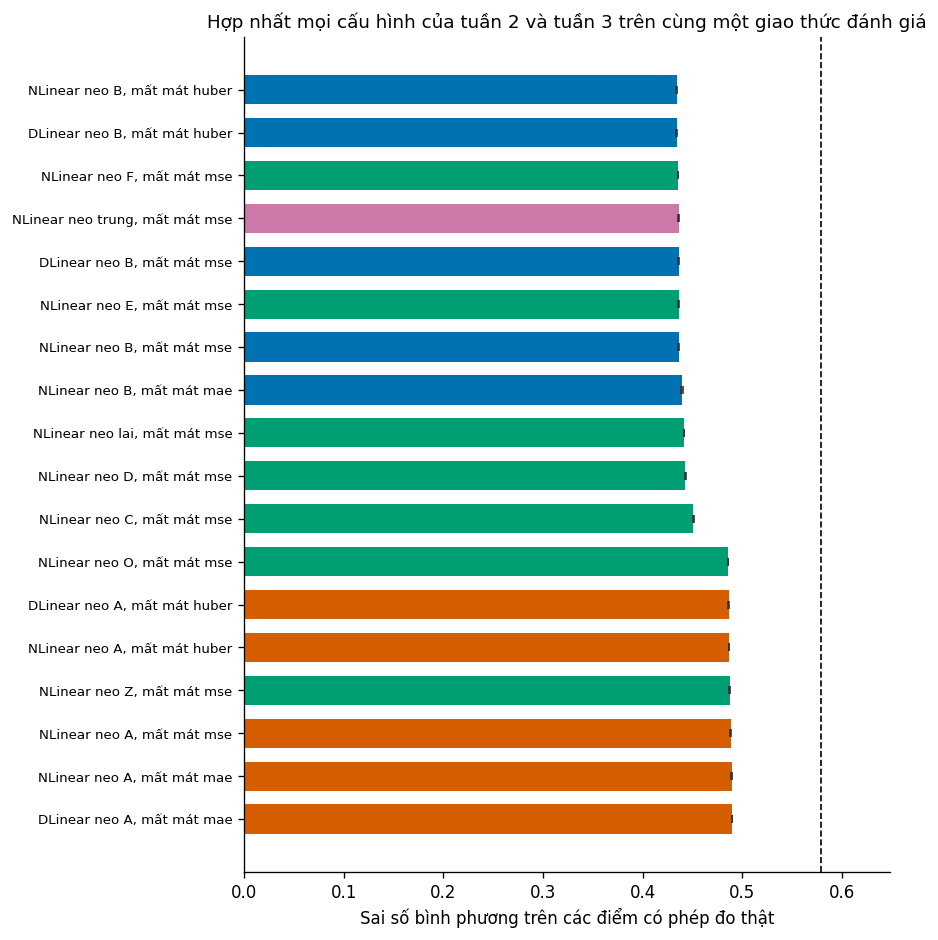

Vạch nét đứt là mốc giữ nguyên dự báo cuối tại 0.578754


In [13]:
nhan = [r["khoa_cau_hinh"].replace("nlinear|", "NLinear neo ").replace(
            "dlinear|", "DLinear neo ").replace("|", ", mất mát ")
        for r in CAU_HINH]
gia_tri = [r["mse_trung_binh"] for r in CAU_HINH]
sai_so = [r["mse_do_lech_chuan"] for r in CAU_HINH]
mau = [PALETTE[0] if r["neo"] == "B" else
       (PALETTE[1] if r["neo"] == "A" else
        (PALETTE[3] if r["neo"] == "trung" else PALETTE[2])) for r in CAU_HINH]

fig, ax = plt.subplots(figsize=(7.4, 0.34 * len(CAU_HINH) + 1.6))
y = np.arange(len(CAU_HINH))
ax.barh(y, gia_tri, xerr=sai_so, color=mau, height=0.68,
        error_kw={"ecolor": "#333333", "capsize": 2.5, "lw": 0.9})
ax.axvline(MSE_MOC, color=PALETTE[6], ls="--", lw=1.0)
ax.set_yticks(y)
ax.set_yticklabels(nhan, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Sai số bình phương trên các điểm có phép đo thật")
ax.set_title("Hợp nhất mọi cấu hình của tuần 2 và tuần 3 trên cùng một giao thức đánh giá")
ax.set_xlim(0.0, max(gia_tri + [MSE_MOC]) * 1.12)
luu_hinh(fig, "W3_T01_thu_hang_cau_hinh.png")
plt.show()
print("Vạch nét đứt là mốc giữ nguyên dự báo cuối tại", round(MSE_MOC, 6))


## 10. Kết luận của sổ tay

Sau khi sổ tay này chạy xong, mọi con số chỉ số của đề tài nằm trong đúng hai tệp bảng và một tệp hợp nhất. Ba quy tắc được chốt lại và các sổ tay sau tuân theo: chỉ tiêu chính là sai số bình phương; khoá cấu hình gồm ba thành phần họ mô hình, neo và hàm mất mát; mọi phát biểu về biến thiên phải gắn tên chỉ tiêu.

In [14]:
print("Artefact đã sinh")
for p in sorted(BANG.glob("*.csv")):
    print("   bảng ", p.name, "|", p.stat().st_size, "byte")
for p in sorted(RUN_DIR.glob("*.json")):
    print("   tệp  ", p.name, "|", p.stat().st_size, "byte")
for p in sorted(FIGS.glob("W3_T*.png")):
    print("   hình ", p.name, "|", p.stat().st_size, "byte")
print("")
print("Bước kế tiếp: chạy notebook 23 để tính lại mọi phép kiểm định trên cùng")
print("một số lần lấy mẫu lặp và cùng một hạt giống lấy mẫu.")


Artefact đã sinh
   bảng  W3_bang_giao_thuc_khac.csv | 155 byte
   bảng  W3_bang_theo_cau_hinh.csv | 3590 byte
   bảng  W3_bang_tung_lan_huan_luyen.csv | 14581 byte
   tệp   W3_HOP_NHAT_CHI_SO.json | 182029 byte
   hình  W3_T01_thu_hang_cau_hinh.png | 253083 byte

Bước kế tiếp: chạy notebook 23 để tính lại mọi phép kiểm định trên cùng
một số lần lấy mẫu lặp và cùng một hạt giống lấy mẫu.
